# Tarea Computacional · IMT2220 Cálculo para Ciencia de Datos (2026-2)
## Problema 2: Red neuronal con dos capas ocultas

**Grupo:** 10

**Integrantes:**
- Lucas Martín Chicao Carmona
- Ignacio Andrés Osorio Orellana
- Martín Ignacio Serrano Pizarro
- Martin Antonio Von Gehr Campos

---

**Antes de entregar**
- Ejecuten todas las celdas en orden, de principio a fin (*Reiniciar kernel y ejecutar todo*), y revisen que no haya errores.
- Solo pueden usar operaciones básicas de `numpy`, funciones para leer los datos y `matplotlib` (ver *Indicaciones para el código* en el enunciado). 
- Los desarrollos y las respuestas van en el informe (PDF). Aquí basta con el código, sus resultados y comentarios breves.
- Para obtener el PDF: en VS Code, menú `···` de la barra superior del notebook → *Exportar* → *HTML*; luego abran el `.html` en el navegador e imprímanlo como PDF.

Reemplacen cada celda marcada con `# TODO` por su código. Pueden agregar todas las celdas que necesiten.

## Configuración

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

FIGURAS = "../informe/figuras"   # el informe toma las figuras directamente desde aquí
os.makedirs(FIGURAS, exist_ok=True)

rng = np.random.default_rng(10)   # semilla fija: mismos resultados en cada ejecución

## Datos

Los archivos `datos_P2.csv` (partes (c) a (f)) y `datos_P2_g.csv` (parte (g)) deben estar en la misma carpeta que este notebook. Tienen una línea de encabezado `x,y` y dos columnas separadas por comas.

N = 200 datos;  x en [-0.990, 0.966],  y en [-0.077, 2.216]


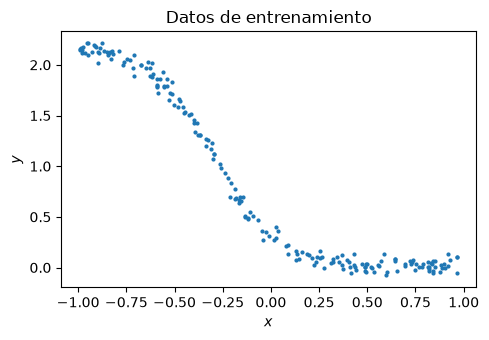

In [2]:
x, y = np.loadtxt("datos_P2.csv", delimiter=",", skiprows=1, unpack=True)
x_g, y_g = np.loadtxt("datos_P2_g.csv", delimiter=",", skiprows=1, unpack=True)
N = len(x)
print(f"N = {N} datos;  x en [{x.min():.3f}, {x.max():.3f}],  y en [{y.min():.3f}, {y.max():.3f}]")

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(x, y, ".", ms=4)
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.set_title("Datos de entrenamiento")
fig.tight_layout()
fig.savefig(f"{FIGURAS}/datos_P2.png", dpi=200)
plt.show()

## Notación

Los parámetros se agrupan, en este orden, en el vector $\theta = (a_1, b_1, a_2, b_2, v, c) \in \mathbb{R}^6$.

## (a) y (b)

## (c) Implementación y verificación del gradiente

In [3]:
# TODO: programar estas funciones, con theta = (a1, b1, a2, b2, v, c).

def sigmoide(t):
    return 1.0 / (1.0 + np.exp(-t))

def d_sigmoide(t):
    return sigmoide(t) * (1 - sigmoide(t))

def predecir(theta, x):
    """Salida de la red, y_hat(x; theta)."""
    a1, b1, a2, b2, v, c = theta
    z1 = a1 * x + b1
    h1 = sigmoide(z1)
    z2 = a2 * h1 + b2
    h2 = sigmoide(z2)
    return c + v * h2


def J(theta, x, y):
    """Función de pérdida J(theta)."""
    y_hat = predecir(theta, x)
    return np.sum((y_hat - y)**2) / (2 * N)



def grad_J(theta, x, y):
    """Gradiente de J en theta, según las fórmulas de (b): arreglo de largo 6."""
    a1, b1, a2, b2, v, c = theta
    N = len(x)
    z1 = a1 * x + b1
    h1 = sigmoide(z1)
    z2 = a2 * h1 + b2
    h2 = sigmoide(z2)
    y_hat = c + v * h2
    e = y_hat - y

    dJ_dc = np.sum(e) / N
    dJ_dv = np.sum(e * h2) / N
    dJ_da2 = np.sum(e * v * d_sigmoide(z2) * h1)  / N
    dJ_db2 = np.sum(e * v * d_sigmoide(z2)) / N
    dJ_da1 = np.sum(e * v * d_sigmoide(z2) * a2 * d_sigmoide(z1) * x) / N
    dJ_db1 = np.sum(e * v * d_sigmoide(z2) * a2 * d_sigmoide(z1)) / N

    return np.array([dJ_da1, dJ_db1, dJ_da2, dJ_db2, dJ_dv, dJ_dc])

In [4]:
# TODO
theta0 = rng.uniform(-1, 1, 6)
print("theta0 =", theta0)
print(f"J(theta0) = {J(theta0, x, y):.6f}")

h = 10**-5
gradiente = grad_J(theta0, x, y)
D_j = np.zeros(6)
for j in range(6):
    theta0_suma, theta0_resta = theta0.copy(), theta0.copy()
    theta0_suma[j] += h
    theta0_resta[j] -= h
    D_j[j] = (J(theta0_suma, x, y) - J(theta0_resta , x, y)) / (2 * h)

print(f"\nComponente    Gradiente theta_0    Diferencias Centradas     Error absoluto")
componentes = ["dJ_da1", "dJ_db1", "dJ_da2", "dJ_db2", "dJ_dv", "dJ_dc"]
for i in range(6):
    print(f"{componentes[i]}         {gradiente[i]:.2e}            {D_j[i]:.2e}                   {abs(gradiente[i] - D_j[i]):.2e}")



Error = np.max(np.abs(gradiente - D_j))
print(f"Error máximo E = {Error:.2e}")

theta0 = [ 0.91200342 -0.58463638  0.65688977 -0.70143575  0.02560923 -0.72816079]
J(theta0) = 1.622869

Componente    Gradiente theta_0    Diferencias Centradas     Error absoluto
dJ_da1         3.17e-04            3.17e-04                   2.72e-12
dJ_db1         -1.23e-03            -1.23e-03                   1.31e-11
dJ_da2         -2.83e-03            -2.83e-03                   1.74e-11
dJ_db2         -9.49e-03            -9.49e-03                   1.38e-11
dJ_dv         -5.95e-01            -5.95e-01                   8.97e-12
dJ_dc         -1.58e+00            -1.58e+00                   2.79e-12
Error máximo E = 1.74e-11


## (d) Descenso del gradiente

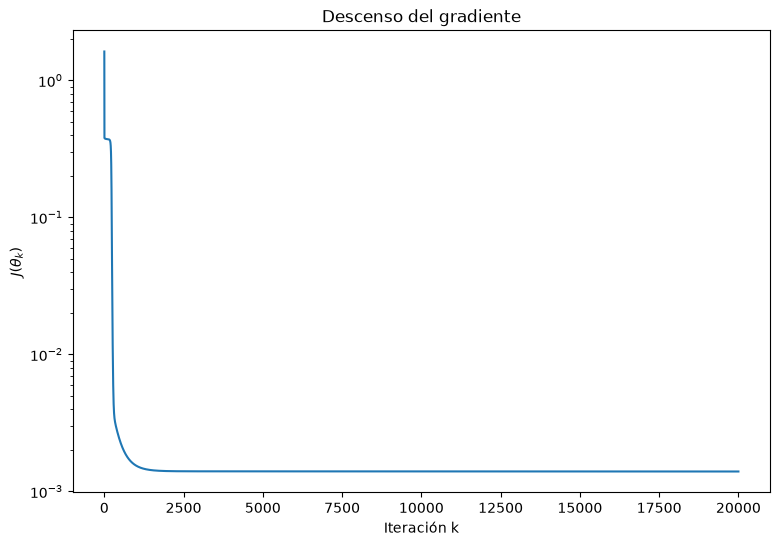

In [5]:
# TODO: programar el descenso del gradiente con paso fijo.

def descenso_gradiente(theta0, x, y, alpha, iteraciones=20_000):
    """Devuelve theta final y los valores J(theta_k) de cada iteración."""
    theta = theta0
    valores = np.zeros(iteraciones + 1)
    valores[0] = J(theta, x, y)
    for k in range(iteraciones):
        theta = theta - alpha * grad_J(theta, x, y)
        valores[k + 1] = J(theta, x, y)
    return theta, valores


# TODO
# - Ejecutarlo desde theta0 con alpha = 1 y 20.000 iteraciones.
# - Graficar J(theta_k) en función de k y guardar en f"{FIGURAS}/P2_d_error.png"
theta_graficar, valores = descenso_gradiente(theta0, x, y, alpha=1, iteraciones=20000)
fig, ax = plt.subplots(figsize=(9,6))
ax.plot(valores)
ax.set_xlabel("Iteración k")
ax.set_ylabel("$J(\\theta_k)$")
ax.set_title("Descenso del gradiente")
ax.set_yscale("log")
fig.savefig(f"{FIGURAS}/P2_d_error.png", dpi=200, bbox_inches="tight")
plt.show()

## (e) Parámetros encontrados

Datos theta_20000 (forma [a1, b1, a2, b2, v, c]):
[ 4.62336208  0.71831521  4.39355706 -0.99011768 -3.17818018  3.08573878]
J(theta_20000) = 0.0013953625538601921


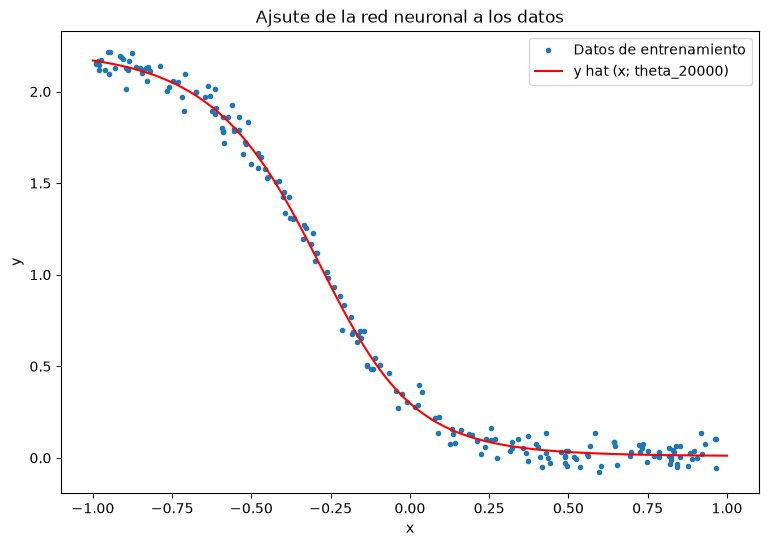

In [6]:
# TODO
# - Reportar theta_20000 y J(theta_20000).
# - Graficar los datos y la curva y_hat en [-1, 1] y guardar en f"{FIGURAS}/P2_e_ajuste.png"
print("Datos theta_20000 (forma [a1, b1, a2, b2, v, c]):")
print(theta_graficar)
print(f"J(theta_20000) = {J(theta_graficar, x, y)}")

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(x, y, ".", label="Datos de entrenamiento")
x_curva = np.linspace(-1, 1, 300)
y_hat_curva = predecir(theta_graficar, x_curva)
ax.plot(x_curva, y_hat_curva, "r-", label="y hat (x; theta_20000)")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Ajsute de la red neuronal a los datos")
ax.legend()
fig.savefig(f"{FIGURAS}/P2_e_ajuste.png", dpi=200, bbox_inches="tight")
plt.show()


## (f) Sensibilidad del entrenamiento

### i. Tamaño del paso

Valor J final para alpha = 0.01: 0.126544
Valor J final para alpha = 0.1: 0.001404
Valor J final para alpha = 1: 0.001395


c:\Users\marti\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\_core\fromnumeric.py:83: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
C:\Users\marti\AppData\Local\Temp\ipykernel_7964\19622391.py:22: RuntimeWarning: overflow encountered in square
  return np.sum((y_hat - y)**2) / (2 * N)
c:\Users\marti\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\_core\fromnumeric.py:83: RuntimeWarning: invalid value encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
C:\Users\marti\AppData\Local\Temp\ipykernel_7964\40781738.py:9: RuntimeWarning: invalid value encountered in subtract
  theta = theta - alpha * grad_J(theta, x, y)


Valor J final para alpha = 2.5: nan


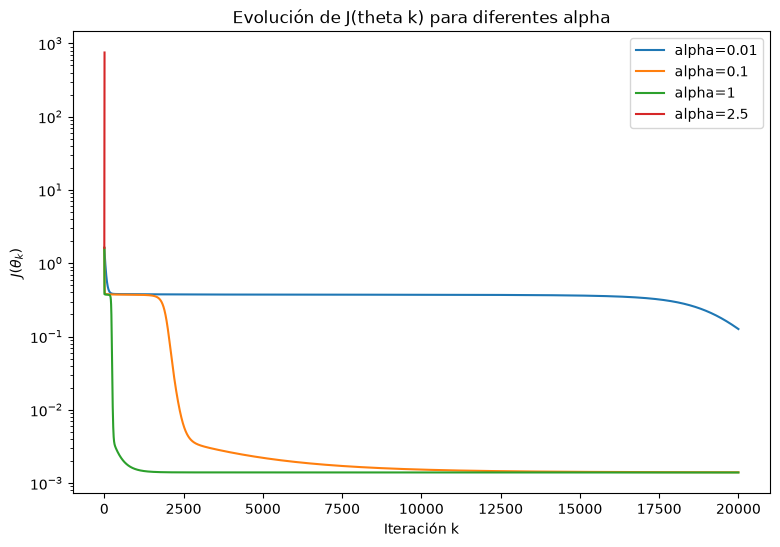

In [7]:
# TODO
# - Repetir (d) desde el mismo theta0 con alpha en {0.01, 0.1, 1, 2.5}.
# - Graficar las cuatro curvas de error juntas y guardar en f"{FIGURAS}/P2_f_pasos.png"
alphas = [0.01, 0.1, 1, 2.5]
fig, ax = plt.subplots(figsize=(9, 6))
for a in alphas:
    theta_graficar, valores_graficar = descenso_gradiente(theta0, x, y, alpha=a, iteraciones=20000)
    print(f"Valor J final para alpha = {a}: {valores_graficar[-1]:.6f}")
    limite = len(valores_graficar)
    for k, valor in enumerate(valores_graficar):
        if not np.isfinite(valor) or valor >= (1000):
            if not np.isfinite(valor):
                print(f"para alpha = {a}, J(theta k) deja de ser un valor finito en la iteración k = {k}")
            limite = k
            break
    ax.plot(valores_graficar[:limite], label=f"alpha={a}")

ax.set_xlabel("Iteración k")
ax.set_ylabel("$J(\\theta_k)$")
ax.set_title("Evolución de J(theta k) para diferentes alpha")
ax.set_yscale("log")
ax.legend()
fig.savefig(f"{FIGURAS}/P2_f_pasos.png", dpi=200, bbox_inches="tight")
plt.show()

### ii. Distintas inicializaciones

inicialización en [-1, 1] #1: Valor final de J = 0.001394
inicialización en [-1, 1] #2: Valor final de J = 0.001395
inicialización en [-1, 1] #3: Valor final de J = 0.001413
inicialización en [-1, 1] #4: Valor final de J = 0.001416
inicialización en [-1, 1] #5: Valor final de J = 0.001410
inicialización en [-1, 1] #6: Valor final de J = 0.001411
inicialización en [-1, 1] #7: Valor final de J = 0.001411
inicialización en [-1, 1] #8: Valor final de J = 0.001392
inicialización en [-1, 1] #9: Valor final de J = 0.001393
inicialización en [-1, 1] #10: Valor final de J = 0.001393


inicialización en [-5, 5] #1: Valor final de J = 0.001392
inicialización en [-5, 5] #2: Valor final de J = 0.001416
inicialización en [-5, 5] #3: Valor final de J = 0.001392
inicialización en [-5, 5] #4: Valor final de J = 0.001392
inicialización en [-5, 5] #5: Valor final de J = 0.001403
inicialización en [-5, 5] #6: Valor final de J = 0.001396
inicialización en [-5, 5] #7: Valor final de J = 0.001404
inicializac

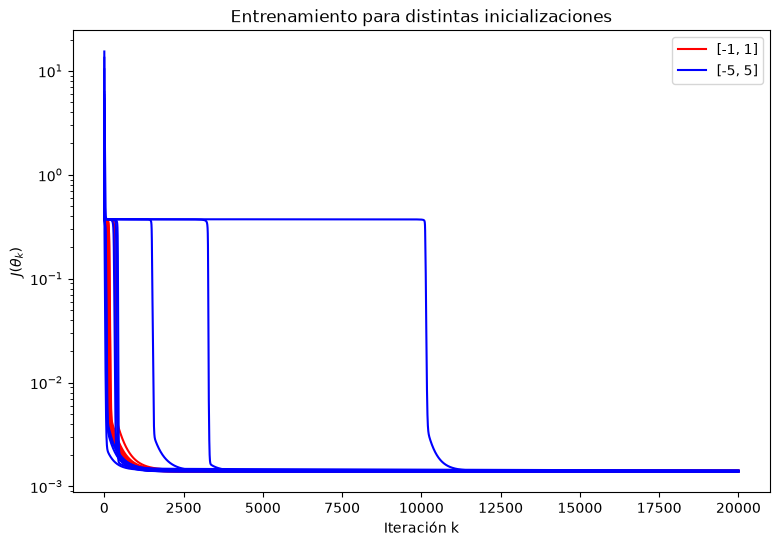

In [8]:
# TODO
# - Repetir (d) con alpha = 1 para 10 inicializaciones en [-1, 1] y 10 en [-5, 5].
# - Reportar el valor final de J de cada una y guardar el gráfico en f"{FIGURAS}/P2_f_inicializaciones.png"
inicializaciones_1 = [rng.uniform(-1, 1, size=6) for i in range(10)]
inicializaciones_5 = [rng.uniform(-5, 5, size=6) for i in range(10)]

fig, ax = plt.subplots(figsize=(9, 6))
for i, theta0_paso_f in enumerate(inicializaciones_1):
    theta_graficar, valores = descenso_gradiente(theta0_paso_f, x, y, alpha=1)
    print(f"inicialización en [-1, 1] #{i+1}: Valor final de J = {valores[-1]:.6f}")
    ax.plot(valores, color="red", label="[-1, 1]" if i == 0 else "")
print(f"\n")
for i, theta0_paso_f in enumerate(inicializaciones_5):
    theta_graficar, valores = descenso_gradiente(theta0_paso_f, x, y, alpha=1)
    print(f"inicialización en [-5, 5] #{i+1}: Valor final de J = {valores[-1]:.6f}")
    ax.plot(valores, color="blue", label="[-5, 5]" if i == 0 else "")

ax.set_xlabel("Iteración k")
ax.set_ylabel("$J(\\theta_k)$")
ax.set_title("Entrenamiento para distintas inicializaciones")
ax.set_yscale("log")
ax.legend()
fig.savefig(f"{FIGURAS}/P2_f_inicializaciones.png", dpi=200, bbox_inches="tight")
plt.show()

## (g) Datos de otra función

### i. Entrenamiento con `datos_P2_g.csv`

J final de datos_P2_g = 7.82e-02
J final de datos_P2 = 1.42e-03


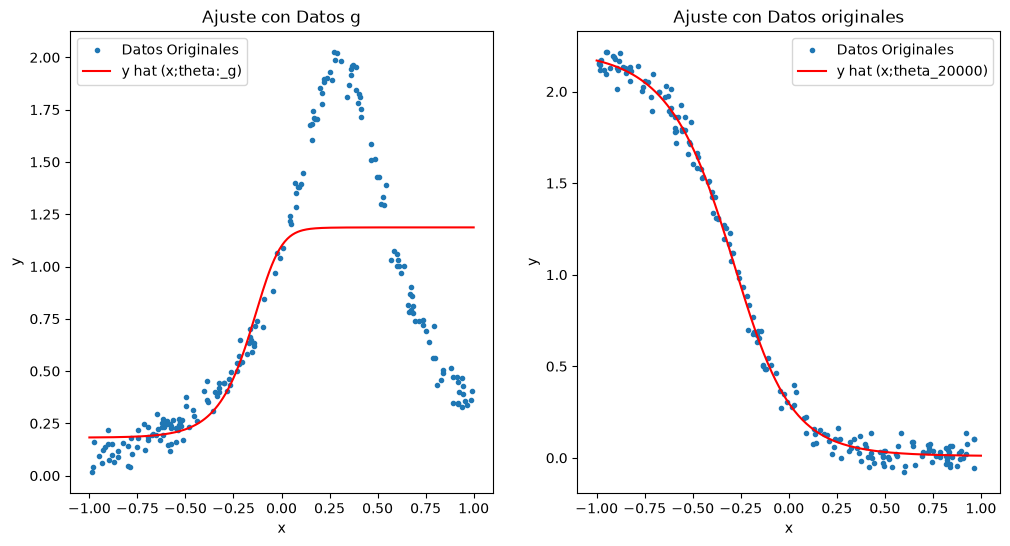

In [9]:
# TODO
# - Entrenar con (x_g, y_g), desde el mismo theta0 de (c), con alpha = 1 y 20.000 iteraciones.
# - Graficar los datos y la curva obtenida y guardar en f"{FIGURAS}/P2_g_ajuste.png"

theta_g, valores_g = descenso_gradiente(theta0, x_g, y_g, alpha=1.0, iteraciones=20000)
print(f"J final de datos_P2_g = {J(theta_g, x_g, y_g):.2e}")
print(f"J final de datos_P2 = {J(theta_graficar, x, y):.2e}")

y_g_curva = predecir(theta_g, x_curva)

fig, axes = plt.subplots(1, 2, figsize=(12,6))
axes[0].plot(x_g,y_g, ".", label="Datos Originales")
axes[0].plot(x_curva, y_g_curva,"r-", label="y hat (x;theta:_g)")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].legend()
axes[0].set_title("Ajuste con Datos g")

axes[1].plot(x, y, ".", label="Datos Originales")
axes[1].plot(x_curva, y_hat_curva,"r-", label="y hat (x;theta_20000)")
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].legend()
axes[1].set_title("Ajuste con Datos originales")
fig.savefig(f"{FIGURAS}/P2_g_ajuste.png", dpi=200, bbox_inches="tight")
plt.show()

### ii.